In [92]:
!pip install opencv-python matplotlib numpy inference-sdk


ERROR: Ignored the following yanked versions: 0.9.0, 0.9.1, 0.9.2, 0.9.3, 0.9.4, 0.9.5, 0.9.6, 0.9.7rc2, 0.9.7, 0.9.8, 0.9.9rc23, 0.9.9, 0.9.10rc3, 0.9.10, 0.9.11rc1, 0.9.11rc2, 0.9.11, 0.9.12rc1, 0.9.12rc3, 0.9.12, 0.9.13, 0.9.14, 0.9.15rc1, 0.9.15, 0.9.16, 0.9.17
ERROR: Ignored the following versions that require a different python version: 0.10.0 Requires-Python >=3.8,<3.12; 0.11.0 Requires-Python >=3.8,<3.12; 0.11.1 Requires-Python >=3.8,<3.12; 0.11.2 Requires-Python >=3.8,<3.12; 0.12.0 Requires-Python >=3.8,<3.12; 0.12.1 Requires-Python >=3.8,<3.12; 0.13.0 Requires-Python >=3.8,<3.12; 0.14.0 Requires-Python >=3.8,<3.12; 0.14.1 Requires-Python >=3.8,<3.12; 0.15.0 Requires-Python >=3.8,<3.12; 0.15.1 Requires-Python >=3.8,<3.12; 0.15.2 Requires-Python >=3.8,<3.12; 0.16.0 Requires-Python >=3.8,<3.12; 0.16.2 Requires-Python >=3.8,<3.12; 0.16.3 Requires-Python >=3.8,<3.12; 0.17.0 Requires-Python >=3.8,<3.12; 0.17.1 Requires-Python >=3.8,<3.12; 0.18.0 Requires-Python >=3.8,<3.12; 0.18.1 

In [93]:
# IMPORTS.
import cv2
import numpy as np
import matplotlib.pyplot as plt
import base64
import requests
from pathlib import Path
import json
import math
import base64
import requests
from io import BytesIO
from PIL import Image

# API STUFF.
ROBOFLOW_API_KEY = "uNmb9cMD2VA4fZBSfKKG"
WORKSPACE_ID = "michael-king-om0es"
CAR_DETECTOR_ID = "2026-f1-season-cars-qronp-2-rfdetr-medium-t1"      
TEAM_CLASSIFIER_ID = "2026-f1-season-cars-qronp-1-rfdetr-large-t1"

WORKING_DIR = Path.cwd()
DATA_DIR = WORKING_DIR / "data"
TEST_IMAGES_DIR = DATA_DIR / "pics"
DRIVER_JSON = DATA_DIR / "drivers-db.json"

In [94]:

def run_rf_detr(image_path, workspace_id, model_id, api_key):
    # Load and regenerate a clean JPEG
    image = Image.open(image_path).convert("RGB")

    buffer = BytesIO()
    image.save(buffer, format="JPEG", quality=95)
    jpeg_bytes = buffer.getvalue()

    image_b64 = base64.b64encode(jpeg_bytes).decode("utf-8")

    # Verify our Base64 locally before sending
    assert base64.b64decode(image_b64, validate=True) == jpeg_bytes

    url = f"https://serverless.roboflow.com/{workspace_id}/{model_id}"

    response = requests.post(
        url,
        params={
            "api_key": api_key,
            "image_type": "base64",
        },
        data=image_b64,
        headers={"Content-Type": "application/json"},
        timeout=120,
    )

    print("URL:", response.request.url.split("?")[0])
    print("Image bytes:", len(jpeg_bytes))
    print("Base64 characters:", len(image_b64))
    print("Response:", response.status_code, response.text)

    response.raise_for_status()
    return response.json()

In [95]:
car_detection_results = run_rf_detr(
    image_path=TEST_IMAGES_DIR / "three-cars-1.jpg",
    workspace_id=WORKSPACE_ID,
    model_id=CAR_DETECTOR_ID,
    api_key=ROBOFLOW_API_KEY
)

print(car_detection_results)

URL: https://serverless.roboflow.com/michael-king-om0es/2026-f1-season-cars-qronp-2-rfdetr-medium-t1
Image bytes: 447034
Base64 characters: 596048
Response: 200 {"inference_id":"d2d4b892-4d8e-45a2-a603-6bf4ad894799","time":0.04265985218808055,"image":{"width":2048,"height":1152},"predictions":[{"x":1124.5,"y":797.5,"width":1247.0,"height":707.0,"confidence":0.9001652002334595,"class":"car","class_id":0,"detection_id":"55d828c4-3180-4969-9352-cfe9a04b163c"},{"x":818.0,"y":447.0,"width":842.0,"height":492.0,"confidence":0.7747474312782288,"class":"car","class_id":0,"detection_id":"f2386ec6-5593-42c7-bc91-c60b8ce9509f"},{"x":528.0,"y":215.5,"width":718.0,"height":431.0,"confidence":0.735396683216095,"class":"car","class_id":0,"detection_id":"8beb3d1c-1edc-43ca-8ca4-6bff0cf0b88a"}]}
{'inference_id': 'd2d4b892-4d8e-45a2-a603-6bf4ad894799', 'time': 0.04265985218808055, 'image': {'width': 2048, 'height': 1152}, 'predictions': [{'x': 1124.5, 'y': 797.5, 'width': 1247.0, 'height': 707.0, 'confi

In [96]:

def annotate_detections(image_path, results):

    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(f"Could not load image: {image_path}")

    image_height, image_width = image.shape[:2]
    result_width = results["image"]["width"]
    result_height = results["image"]["height"]

    scale_x = image_width / result_width
    scale_y = image_height / result_height

    for prediction in results.get("predictions", []):

        x = prediction["x"]
        y = prediction["y"]
        
        width = prediction["width"]
        height = prediction["height"]

        x1 = round((x - width / 2) * scale_x)
        y1 = round((y - height / 2) * scale_y)
        x2 = round((x + width / 2) * scale_x)
        y2 = round((y + height / 2) * scale_y)

        # Keep coordinates inside the image.
        x1 = max(0, min(x1, image_width - 1))
        y1 = max(0, min(y1, image_height - 1))
        x2 = max(0, min(x2, image_width - 1))
        y2 = max(0, min(y2, image_height - 1))

        label = prediction.get("class", "object")
        confidence = prediction.get("confidence", 0)
        caption = f"{label} {confidence:.1%}"

        color = (0, 0, 255)  # Red in BGR
        thickness = 2

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            color,
            thickness,
        )

        font = cv2.FONT_HERSHEY_SIMPLEX
        font_scale = 0.6
        text_thickness = 2

        (text_width, text_height), baseline = cv2.getTextSize(
            caption,
            font,
            font_scale,
            text_thickness,
        )

        label_y1 = max(0, y1 - text_height - baseline - 8)

        cv2.rectangle(
            image,
            (x1, label_y1),
            (min(image_width - 1, x1 + text_width + 8), y1),
            color,
            -1,
        )

        cv2.putText(
            image,
            caption,
            (x1 + 4, max(text_height, y1 - baseline - 4)),
            font,
            font_scale,
            (255, 255, 255),
            text_thickness,
            cv2.LINE_AA,
        )

    return image

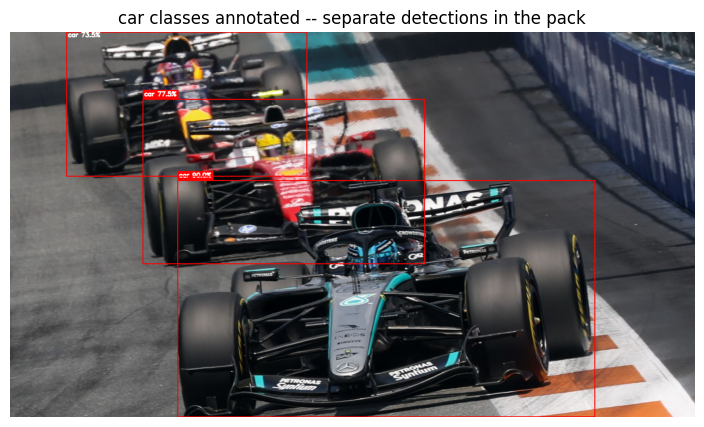

In [97]:
annotated_image = annotate_detections(TEST_IMAGES_DIR / "three-cars-1.jpg", car_detection_results)

annotated_image_bgr = cv2.cvtColor(
        annotated_image,
        cv2.COLOR_BGR2RGB,
    )


plt.figure(figsize=(10, 5))
plt.imshow(annotated_image_bgr)
plt.title(f"car classes annotated -- separate detections in the pack")
plt.axis("off")
plt.show()

Created 3 crops.


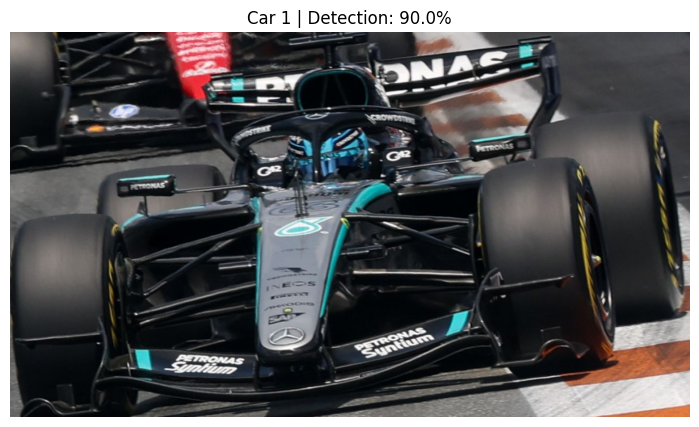

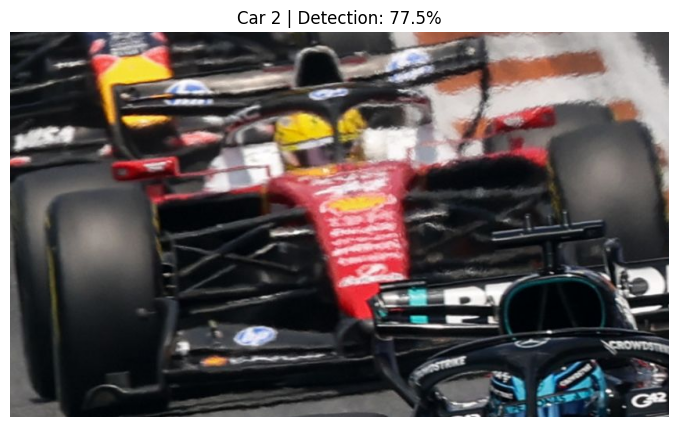

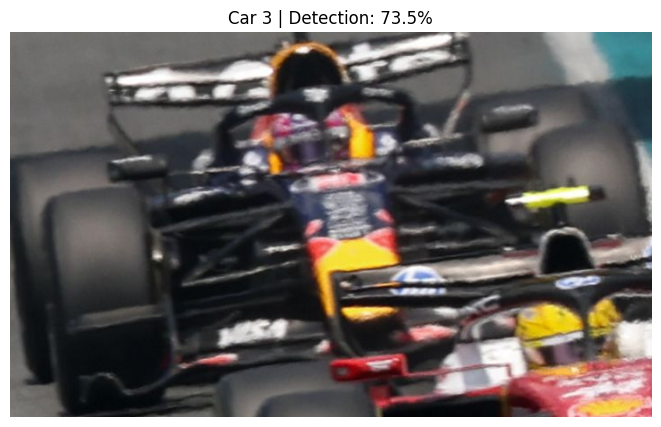

In [ ]:
predictions = car_detection_results.get("predictions", [])
num_cars = len(predictions)

plain_image = cv2.imread(
    str(TEST_IMAGES_DIR / "three-cars-1.jpg")
)

if plain_image is None:
    raise FileNotFoundError("Could not load three-cars-1.jpg")

image_h, image_w = plain_image.shape[:2]

result_w = car_detection_results["image"]["width"]
result_h = car_detection_results["image"]["height"]

scale_x = image_w / result_w
scale_y = image_h / result_h

crops = []

padding = 0.05  # 5% padding around the detected box

for i, pred in enumerate(predictions):
    x1 = max(
        0,
        round((pred["x"] - pred["width"] / 2) * scale_x),
    )
    y1 = max(
        0,
        round((pred["y"] - pred["height"] / 2) * scale_y),
    )
    x2 = min(
        image_w,
        round((pred["x"] + pred["width"] / 2) * scale_x),
    )
    y2 = min(
        image_h,
        round((pred["y"] + pred["height"] / 2) * scale_y),
    )

    # Apply padding to the crop region
    pad_x = int((x2 - x1) * padding)
    pad_y = int((y2 - y1) * padding)
    x1 = max(0, x1 - pad_x)
    y1 = max(0, y1 - pad_y)
    x2 = min(image_w, x2 + pad_x)
    y2 = min(image_h, y2 + pad_y)

    car_crop_bgr = plain_image[y1:y2, x1:x2].copy()

    if car_crop_bgr.size == 0:
        continue

    car_crop_rgb = cv2.cvtColor(
        car_crop_bgr,
        cv2.COLOR_BGR2RGB,
    )

    crops.append({
        "car_id": i + 1,
        "car_confidence": pred["confidence"],
        "crop_bgr": car_crop_bgr,
        "crop_rgb": car_crop_rgb,
        "box": (x1, y1, x2, y2),
        "car_prediction": pred,
    })

print(f"Created {len(crops)} crops.")

for crop_record in crops:
    plt.figure(figsize=(10, 5))
    plt.imshow(crop_record["crop_rgb"])
    plt.title(
        f"Car {crop_record['car_id']} | "
        f"Detection: {crop_record['car_confidence']:.1%}"
    )
    plt.axis("off")
    plt.show()

In [100]:
from pathlib import Path
import math
import cv2
import matplotlib.pyplot as plt


classified_cars = []
output_dir = Path("./data/out")
output_dir.mkdir(parents=True, exist_ok=True)

# Classify every detected car crop.
for car_id, car_crop_rgb in enumerate(crops, start=1):


    output_path = output_dir / f"car_{car_id}.jpg"

    saved_success = cv2.imwrite(
        str(output_path),
        car_crop_rgb['crop_bgr'],
        [cv2.IMWRITE_JPEG_QUALITY, 95],
    )

    if not saved_success:
        print(f"Could not save car {car_id}")
        continue

    # One team-classifier API call per crop.
    team_result = run_rf_detr(
        image_path=output_path,
        workspace_id=WORKSPACE_ID,
        model_id=TEAM_CLASSIFIER_ID,
        api_key=ROBOFLOW_API_KEY,
    )

    team_predictions = team_result.get("predictions", [])

    if team_predictions:
        best_prediction = max(
            team_predictions,
            key=lambda prediction: prediction["confidence"],
        )

        car_model = best_prediction["class"]
        team_confidence = best_prediction["confidence"]
    else:
        best_prediction = None
        car_model = "Unknown Team"
        team_confidence = 0.0

    # Keep the crop and its prediction together in memory.
    classified_cars.append({
        "car_id": car_id,
        "crop_rgb": car_crop_rgb,
        "crop_bgr": car_crop_bgr,
        "car_model": car_model,
        "confidence": team_confidence,
        "best_prediction": best_prediction,
        "team_result": team_result,
        "output_path": output_path,
    })

    print(
        f"Car {car_id}: {car_model} "
        f"({team_confidence:.1%})"
    )

URL: https://serverless.roboflow.com/michael-king-om0es/2026-f1-season-cars-qronp-1-rfdetr-large-t1
Image bytes: 255122
Base64 characters: 340164
Response: 200 {"inference_id":"c9fa285b-a0ea-4220-959a-33f28b5110a6","time":0.09481394430622458,"image":{"width":1247,"height":707},"predictions":[{"x":622.0,"y":351.0,"width":1240.0,"height":702.0,"confidence":0.9327759742736816,"class":"Mercedes W17","class_id":8,"detection_id":"9ba0ead3-215f-4d73-81ce-0bc8141eb7f1"},{"x":200.0,"y":120.0,"width":400.0,"height":240.0,"confidence":0.519146740436554,"class":"Ferrari SF-26","class_id":5,"detection_id":"b64d732f-54fe-4941-83b3-1fb6889c7885"}]}
Car 1: Mercedes W17 (93.3%)
URL: https://serverless.roboflow.com/michael-king-om0es/2026-f1-season-cars-qronp-1-rfdetr-large-t1
Image bytes: 132703
Base64 characters: 176940
Response: 200 {"inference_id":"0b93907c-f18f-45d2-bc05-9978c189e37d","time":0.07953380793333054,"image":{"width":842,"height":492},"predictions":[{"x":421.5,"y":245.0,"width":839.0,"he

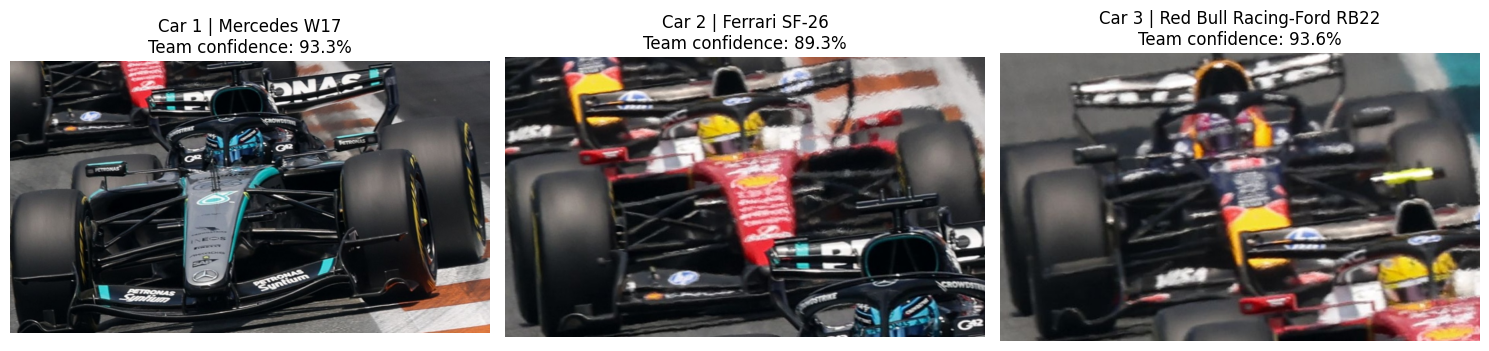

In [101]:
if classified_cars:
    cols = 3
    rows = math.ceil(len(classified_cars) / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(15, 5 * rows),
        squeeze=False,
    )

    axes = axes.flatten()

    for axis, car in zip(axes, classified_cars):
        # Reload the successfully saved crop.
        crop_bgr = cv2.imread(str(car["output_path"]))
        crop_rgb = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB) if crop_bgr is not None else None

        if crop_rgb is None:
            axis.set_title(f"Could not load Car {car['car_id']}")
            axis.axis("off")
            continue


        axis.imshow(crop_rgb)
        axis.set_title(
            f"Car {car['car_id']} | {car['car_model']}\n"
            f"Team confidence: {car['confidence']:.1%}"
        )
        axis.axis("off")

    for axis in axes[len(classified_cars):]:
        axis.axis("off")

    plt.tight_layout()
    plt.show()

In [102]:
def detect_tcam_color(
    tcam_crop,
    yellow_ratio_threshold=0.004,
    return_debug=False,
):

    if tcam_crop is None or tcam_crop.size == 0:
        result = "unknown"
        return (result, {}) if return_debug else result

    hsv = cv2.cvtColor(tcam_crop, cv2.COLOR_BGR2HSV)

    # Fluorescent yellow range. The lower hue excludes most orange liveries.
    lower_yellow = np.array([20, 90, 100], dtype=np.uint8)
    upper_yellow = np.array([45, 255, 255], dtype=np.uint8)

    yellow_mask = cv2.inRange(
        hsv,
        lower_yellow,
        upper_yellow,
    )

    # Remove isolated noise and connect nearby yellow pixels.
    kernel = np.ones((3, 3), dtype=np.uint8)

    yellow_mask = cv2.morphologyEx(
        yellow_mask,
        cv2.MORPH_OPEN,
        kernel,
    )
    yellow_mask = cv2.morphologyEx(
        yellow_mask,
        cv2.MORPH_CLOSE,
        kernel,
    )

    crop_area = tcam_crop.shape[0] * tcam_crop.shape[1]
    yellow_pixels = cv2.countNonZero(yellow_mask)
    yellow_ratio = yellow_pixels / crop_area

    # Require a coherent yellow region, not scattered livery pixels.
    number_of_labels, _, stats, _ = (
        cv2.connectedComponentsWithStats(yellow_mask)
    )

    if number_of_labels > 1:
        largest_yellow_region = int(
            stats[1:, cv2.CC_STAT_AREA].max()
        )
    else:
        largest_yellow_region = 0

    minimum_region_area = max(8, round(crop_area * 0.001))

    is_yellow = (
        yellow_ratio >= yellow_ratio_threshold
        and largest_yellow_region >= minimum_region_area
    )

    return "yellow" if is_yellow else "black"


Car 1: Mercedes W17 | T-cam: black


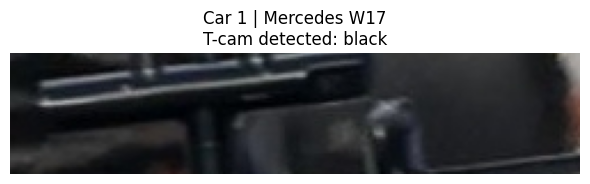

Car 2: Ferrari SF-26 | T-cam: black


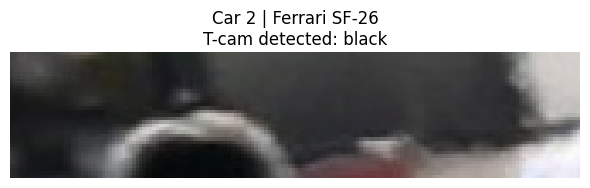

Car 3: Red Bull Racing-Ford RB22 | T-cam: black


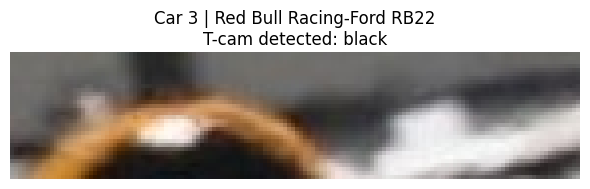

In [103]:
valid_tcam_results = []

for car in classified_cars:
    # Load the corresponding saved car crop as BGR.
    car_crop_bgr = cv2.imread(str(car["output_path"]))

    if car_crop_bgr is None:
        car["tcam_color"] = "unknown"
        car["tcam_crop_bgr"] = None
        continue

    car_h, car_w = car_crop_bgr.shape[:2]

    # Your chosen T-cam search region.
    y1 = 0
    y2 = max(1, round(car_h * 0.075))
    x1 = round(car_w * 0.4)
    x2 = max(x1 + 1, round(car_w * 0.6))

    tcam_crop_bgr = car_crop_bgr[y1:y2, x1:x2]

    if tcam_crop_bgr.size == 0:
        tcam_color = "unknown"
    else:
        # detect_tcam_color expects an OpenCV BGR image.
        tcam_color = detect_tcam_color(tcam_crop_bgr)

    # Add the result to the existing in-memory car record.
    car["tcam_color"] = tcam_color
    car["tcam_crop_bgr"] = tcam_crop_bgr

    valid_tcam_results.append(car)

    print(
        f"Car {car['car_id']}: {car['car_model']} | "
        f"T-cam: {tcam_color}"
    )

        # Convert BGR to RGB for Matplotlib.
    tcam_crop_rgb = cv2.cvtColor(
        tcam_crop_bgr,
        cv2.COLOR_BGR2RGB,
    )

    title_color = {
        "yellow": "goldenrod",
        "black": "black",
        "unknown": "gray",
    }.get(tcam_color, "gray")

    plt.figure(figsize=(6, 3))
    plt.imshow(tcam_crop_rgb)
    plt.title(
        f"Car {car['car_id']} | {car['car_model']}\n"
        f"T-cam detected: {tcam_color}",
        color=title_color,
    )
    plt.axis("off")
    plt.tight_layout()
    plt.show()



In [104]:
import re


TEAM_ALIASES = {
    "McLaren": [
        "mclaren",
    ],
    "Ferrari": [
        "ferrari",
    ],
    "Red Bull Racing": [
        "red bull racing",
        "red bull",
    ],
    "Mercedes": [
        "mercedes",
        "mercedes amg",
    ],
    "Aston Martin": [
        "aston martin",
    ],
    "Williams": [
        "williams",
    ],
    "Alpine": [
        "alpine",
    ],
    "Haas": [
        "haas",
    ],
    "RB": [
        "racing bulls",
        "visa cash app rb",
        "vcarb",
    ],
    "Audi": [
        "audi",
    ],
    "Cadillac": [
        "cadillac",
    ],
}


def normalize_text(value):
    """Lowercase and replace punctuation with spaces."""
    return " ".join(
        re.findall(r"[a-z0-9]+", value.casefold())
    )


def contains_phrase(text, phrase):
    """Match a normalized whole phrase, not arbitrary characters."""
    return f" {phrase} " in f" {text} "


def resolve_team(car_model, driver_db):

    normalized_model = normalize_text(car_model)

    # Include database keys themselves as aliases.
    candidates = []

    for team in driver_db:
        aliases = TEAM_ALIASES.get(team, [])
        aliases = [team, *aliases]

        for alias in aliases:
            normalized_alias = normalize_text(alias)
            candidates.append((
                normalized_alias,
                team,
            ))

    # Prefer longer, more specific aliases.
    candidates.sort(
        key=lambda item: len(item[0]),
        reverse=True,
    )

    for alias, team in candidates:
        if contains_phrase(normalized_model, alias):
            return team

    return None


def load_json(json_path):

    json_path = Path(json_path)

    with json_path.open("r", encoding="utf-8") as file:
        return json.load(file)


driver_db = load_json(DRIVER_JSON)

team = resolve_team(car_model, driver_db)

print(team)


Red Bull Racing


In [105]:
def lookup_driver(car_model, tcam_color, driver_db):
    team = resolve_team(car_model, driver_db)

    if team is None:
        return {
            "team": None,
            "tcam": tcam_color,
            "driver": "Unknown Driver",
            "number": None,
        }

    normalized_tcam = normalize_text(tcam_color)

    if normalized_tcam not in {"black", "yellow"}:
        return {
            "team": team,
            "tcam": normalized_tcam,
            "driver": "Unknown Driver",
            "number": None,
        }

    driver_record = (
        driver_db
        .get(team, {})
        .get(normalized_tcam)
    )

    if driver_record is None:
        return {
            "team": team,
            "tcam": normalized_tcam,
            "driver": "Unknown Driver",
            "number": None,
        }

    return {
        "team": team,
        "tcam": normalized_tcam,
        "driver": driver_record["driver"],
        "number": driver_record["number"],
    }

In [106]:
driver_results = []

for car in classified_cars:
    car_model = car["car_model"]
    tcam_color = car.get("tcam_color", "unknown")

    driver_result = lookup_driver(
        car_model,
        tcam_color,
        driver_db,
    )

    # Store driver information with the existing car record.
    car["driver_result"] = driver_result
    car["driver"] = driver_result["driver"]
    car["team"] = driver_result["team"]
    car["number"] = driver_result["number"]

    driver_results.append(car)

    print(
        f"Car {car['car_id']}: "
        f"{driver_result['driver']} | "
        f"{driver_result['team']} | "
        f"#{driver_result['number']} | "
        f"{car_model}"
    )

Car 1: George Russell | Mercedes | #63 | Mercedes W17
Car 2: Charles Leclerc | Ferrari | #16 | Ferrari SF-26
Car 3: Max Verstappen | Red Bull Racing | #3 | Red Bull Racing-Ford RB22


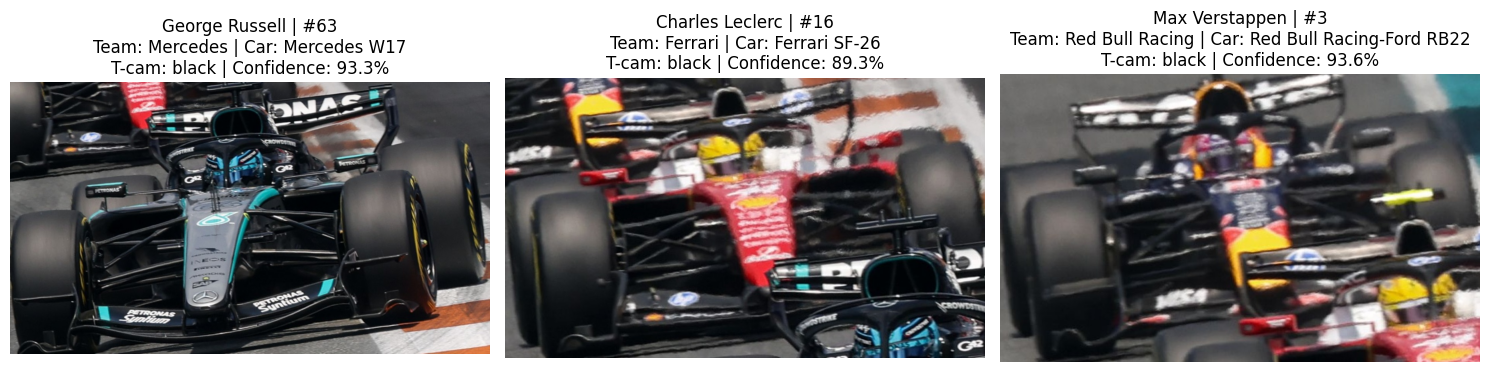

In [107]:
if driver_results:
    cols = 3
    rows = math.ceil(len(driver_results) / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(15, 5 * rows),
        squeeze=False,
    )

    axes = axes.flatten()

    for axis, car in zip(axes, driver_results):
        car_crop_bgr = cv2.imread(str(car["output_path"]))

        if car_crop_bgr is None:
            axis.set_title(f"Could not load Car {car['car_id']}")
            axis.axis("off")
            continue

        car_crop_rgb = cv2.cvtColor(
            car_crop_bgr,
            cv2.COLOR_BGR2RGB,
        )

        number = (
            car["number"]
            if car["number"] is not None
            else "Unknown"
        )

        axis.imshow(car_crop_rgb)
        axis.set_title(
            f"{car['driver']} | #{number}\n"
            f"Team: {car['team']} | Car: {car['car_model']}\n"
            f"T-cam: {car['tcam_color']} | "
            f"Confidence: {car['confidence']:.1%}"
        )
        axis.axis("off")

    for axis in axes[len(driver_results):]:
        axis.axis("off")

    plt.tight_layout()
    plt.show()